# Micheal

1. Fast / slow: cue-aligned alpha-band time courses.
2. Cue alignment: time-frequency maps and alpha-band time courses.
3. Hand-target same / different: comparison of band time courses.
4. Each Cn / In pair: contra − ipsi alpha-band time courses.
5. Response-hand alignment: early / late band time courses.
6. Midline: mean-power band time courses.


In [1]:

# Locate the project independently of the machine and Jupyter launch directory.
import os as _path_os
import sys as _path_sys
from pathlib import Path as _ProjectPath
_path_start = _ProjectPath(__file__).resolve().parent if '__file__' in globals() else _ProjectPath.cwd()
_path_roots = ([_ProjectPath(_path_os.environ['TRAVELLING_WAVES_ROOT']).expanduser()]
               if _path_os.environ.get('TRAVELLING_WAVES_ROOT') else [])
_path_roots += [_path_start, *_path_start.parents]
_path_root = next((p for p in _path_roots if (p / 'project_locations.py').is_file()), None)
if _path_root is None:
    _path_roots = [p for mount, pattern in [('/Volumes', '*/travelling_waves'),
                    ('/media', '*/*/travelling_waves'), ('/mnt', '*/travelling_waves')]
                   for p in _ProjectPath(mount).glob(pattern)
                   if (p / 'project_locations.py').is_file()]
    if len(_path_roots) != 1:
        raise FileNotFoundError('Cannot uniquely locate travelling_waves. Set TRAVELLING_WAVES_ROOT to its directory.')
    _path_root = _path_roots[0]
_path_sys.path.insert(0, str(_path_root))
from project_locations import project_path, font_path

from pathlib import Path
import sys
import platform
import importlib
import pickle
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path(project_path())
PLOT_DIR = PROJECT_ROOT / 'tw/decoding_gpu'
sys.path.insert(0, str(PLOT_DIR))
print(f'System: {platform.system()} | Project: {PROJECT_ROOT}')
from functions.tw_funcs import tw_plot_funcs as plots
plots = importlib.reload(plots)


System: Darwin | Project: /Volumes/T7/travelling_waves


In [2]:
MEASURES = ['fw', 'bw']
CORRECT_ONLY = False
N_PERMUTATIONS = 5000
SEED = 42
ALPHA = 0.05
CONTRA_LINES = ['C5', 'C4', 'C3', 'C2', 'C1']
IPSI_LINES = ['I1', 'I2', 'I3', 'I4', 'I5']
RELATIVE_LINES = ['C5', 'C4', 'C3', 'C2', 'C1', 'M', 'I1', 'I2', 'I3', 'I4', 'I5']
LINE_GROUPS = {
    'contra': [RELATIVE_LINES.index(x) for x in CONTRA_LINES],
    'ipsi': [RELATIVE_LINES.index(x) for x in IPSI_LINES],
    'mid': [5],
}
BAND_YLIMS = {'fw': (-.15, .15), 'bw': (-.15, .15)}
HAND_YLIMS = {'fw': (-.15, .15), 'bw': (-.15, .15)}
POWER_YLIMS = {'fw': (-0.4, 0.4), 'bw': (-0.4, 0.4)}
RESULT_DIR = PROJECT_ROOT / 'tw/result/micheal_fft'
FIG_DIR = PROJECT_ROOT / 'tw/result/figs/micheal'
MAX_RT = 1.5
RT_REMOVE = True
EXCLUDE_BAD_EPOCH = True
EXCLUDE_SUBJECTS = set()
FREQ_BANDS = [(2, 6, 'theta (2–6 Hz)'), (8, 12, 'alpha (8–12 Hz)'),
              (14, 30, 'beta (14–30 Hz)')]
# Cue time courses: choose frequency bands and direction layout here.
CUE_FREQ_BANDS = [FREQ_BANDS[1]]  # alpha (8–12 Hz); use FREQ_BANDS for all three.
CUE_MEASURE_LAYOUT = 'horizontal'  # 'horizontal' or 'vertical'
PROBE_ONSET = {'early': 1.8, 'late': 4.3}
EVENTS = [(0, 'target onset'), (1.2, 'impulse1'), (1.8, 'probe1'),
          (3.8, 'impulse2'), (4.3, 'probe2')]
STIMULUS_BARS = [(0, .250), (1.2, .100), (1.8, .250), (3.8, .100), (4.3, .250)]
PLOT_WINDOWS = {
    'early': dict(t_start=1.55, t_stop=4.3, time_zero=1.8),
    'late': dict(t_start=4.05, t_stop=5.6, time_zero=4.3),
    'whole': dict(t_start=-1.2, t_stop=6.0, time_zero=0.0),  # Full epoch; target onset = 0 s.
}
# True: combine directions; cue time courses use CUE_MEASURE_LAYOUT.
# False: use separate figures (except calls explicitly setting split_measures=False).
COMBINE_MEASURES = True
PLOT_OPTIONS = dict(events=EVENTS, stimulus_bars=STIMULUS_BARS,
                    combine_measures=COMBINE_MEASURES,
                    n_perm=N_PERMUTATIONS, seed=SEED, alpha=ALPHA)

# TF colorbar endpoints are ± these values, in dB.
TF_LIMITS = {'fw': .30, 'bw': .30}
TF_DIFF_LIMITS = {'fw': .04, 'bw': .04}
TF_CMAP = 'coolwarm'
TF_SHOW_SIDES = False  # True also plots contra, ipsi and midline.
TF_PANEL_SIZE = (6.4, 4.8)


In [3]:
METADATA_KEYS = ('time', 'ff', 'cue_loc', 'early_rot', 'late_rot', 'early_acc',
                 'late_acc', 'early_rt', 'late_rt', 'is_bad_epoch')
SESSION_PATHS = sorted(RESULT_DIR.glob('subj*_sess*.pkl'))
SESSION_PATHS = [path for path in SESSION_PATHS
                 if int(re.search(r'subj(\d+)', path.name)[1]) not in EXCLUDE_SUBJECTS]
metadata = {}

def session_metadata(path):
    if path not in metadata:
        with path.open('rb') as stream:
            data = pickle.load(stream)
        metadata[path] = {key: data[key] for key in METADATA_KEYS}
    return metadata[path]

def subject_id(path):
    return int(re.search(r'subj(\d+)', path.name)[1])

def trial_mask(data):
    keep = np.ones(len(data['early_rt']), dtype=bool)
    if RT_REMOVE:
        keep &= ~np.isnan(data['early_rt']) & (data['late_rt'] <= MAX_RT)
    if EXCLUDE_BAD_EPOCH:
        keep &= ~np.asarray(data['is_bad_epoch'], bool)
    if CORRECT_ONLY:
        keep &= (data['early_acc'] == 1) & (data['late_acc'] == 1)
    return keep

def response_left(data, rt_type):
    return ((data[rt_type+'_rot'] == 1) & (data[rt_type+'_acc'] == 1)
            | (data[rt_type+'_rot'] != 1) & (data[rt_type+'_acc'] == 0))

def alignment_mask(data, alignment, rt_type):
    if alignment == 'hand':
        return response_left(data, rt_type)
    if alignment == 'cue':
        return np.full(len(data['early_rt']), data['cue_loc'][0] == 2)
    return np.zeros(len(data['early_rt']), bool)

def condition_masks(data, rt_type, comparison, median_rt):
    keep = trial_mask(data)
    if comparison == 'hand_target':
        late_left = data['cue_loc'] == 2
        target_left = late_left if rt_type == 'late' else ~late_left
        same = response_left(data, rt_type) == target_left
        return {'same': keep & same, 'different': keep & ~same}
    if comparison == 'fast_slow':
        rt = data[rt_type+'_rt']
        return {'fast': keep & (rt < median_rt), 'slow': keep & (rt > median_rt)}
    return {'all': keep}

def prepare_maps(*, alignment, rt_type, comparison='all', groups=LINE_GROUPS):
    # Fast/slow uses each subject's pooled-session median; ties are omitted.
    medians = {}
    if comparison == 'fast_slow':
        for subject in sorted({subject_id(path) for path in SESSION_PATHS}):
            rt = [session_metadata(path)[rt_type+'_rt'][trial_mask(session_metadata(path))]
                  for path in SESSION_PATHS if subject_id(path) == subject]
            medians[subject] = np.median(np.concatenate(rt))
    def sessions():
        for path in SESSION_PATHS:
            meta = session_metadata(path)
            subject = subject_id(path)
            with path.open('rb') as stream:
                data = pickle.load(stream)
            time = -1.2 + (np.asarray(data['time'])+125)/500
            power = plots.normalize_power(data['fwmax'], data['fwssmax'], data['bwmax'], data['bwssmax'])
            del data
            yield dict(subject=subject, session=path.stem, time=time, frequencies=np.asarray(meta['ff']), power=power, selections=condition_masks(meta, rt_type, comparison, medians.get(subject)), flip=alignment_mask(meta, alignment, rt_type), rt={key: np.asarray(meta[key]) for key in ('early_rt', 'late_rt')})
    return plots.collect_maps(sessions(), groups=groups, align=alignment != 'physical',
                              weighting='trial' if comparison == 'fast_slow' else 'session')

def rt_lines(data):
    return [(PROBE_ONSET[key]+np.mean(np.concatenate(list(data['rt'][key+'_rt'].values()))), color, key+' RT')
            for key, color in [('early', 'red'), ('late', 'green')]]

def output_dir():
    return FIG_DIR / 'no-bl'


In [4]:
rows = []
for path in SESSION_PATHS:
    data = session_metadata(path)
    n = len(data['early_rt'])
    keep = trial_mask(data)
    rows.append(dict(subject=subject_id(path), total=n, kept=int(keep.sum()),
        early_correct=int((data['early_acc']==1).sum()),
        late_correct=int((data['late_acc']==1).sum()),
        #both_correct=int(((data['early_acc']==1)&(data['late_acc']==1)).sum()),
        bad_epoch=int(np.asarray(data['is_bad_epoch'], bool).sum()),
        early_rt=data['early_rt'][keep],
        late_rt=data['late_rt'][keep]))
trial_summary = pd.DataFrame(rows).groupby('subject').agg(
    total=('total','sum'), kept=('kept','sum'), #both_correct=('both_correct','sum'),
    early_correct=('early_correct','sum'), late_correct=('late_correct','sum'),
    bad_epoch=('bad_epoch','sum'),
    early_rt_mean=('early_rt', lambda rt: np.mean(np.concatenate(rt.to_list()))),
    late_rt_mean=('late_rt', lambda rt: np.mean(np.concatenate(rt.to_list()))))
trial_summary['early_acc_mean'] = trial_summary.pop('early_correct') / trial_summary['total']
trial_summary['late_acc_mean'] = trial_summary.pop('late_correct') / trial_summary['total']
trial_summary['kept_percent'] = 100*trial_summary.kept/trial_summary.total
display(trial_summary)
print('Subjects:', trial_summary.index.tolist())


,total,kept,bad_epoch,early_rt_mean,late_rt_mean,early_acc_mean,late_acc_mean,kept_percent
subject,,,,,,,,
1,1728,1518,189,0.458116,0.470532,0.817130,0.723380,87.847222
2,1727,1600,78,0.563274,0.551188,0.704690,0.524030,92.646207
3,1728,1346,374,0.491378,0.563330,0.865162,0.818866,77.893519
4,1728,1571,139,0.501461,0.539046,0.851852,0.681134,90.914352
5,1726,1549,149,0.533211,0.561462,0.879490,0.856895,89.745075
6,1728,1508,200,0.541234,0.555128,0.799190,0.671296,87.268519
7,1727,1504,187,0.581826,0.598857,0.773596,0.678054,87.087435
8,1728,1468,220,0.505175,0.474933,0.841435,0.723958,84.953704
9,1728,1418,249,0.540888,0.575224,0.762731,0.662037,82.060185


Subjects: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


In [5]:
# Group-level behavioral summary: each subject contributes equally.
# Preserve the trial definitions used in trial_summary above.
subject_behavior = pd.DataFrame({
    'Early RT (s)': trial_summary['early_rt_mean'],
    'Late RT (s)': trial_summary['late_rt_mean'],
    'Early accuracy (%)': 100 * trial_summary['early_acc_mean'],
    'Late accuracy (%)': 100 * trial_summary['late_acc_mean'],
})
group_summary = subject_behavior.agg(['count', 'mean', 'std', 'sem']).T
group_summary = group_summary.rename(columns={'count': 'n_subjects', 'std': 'sd'})
group_summary['n_subjects'] = group_summary['n_subjects'].astype(int)
group_summary.index.name = 'measure'
print('Group-level behavior (equal weight per subject):')
print('RT: retained trials; accuracy: all trials before trial filtering.')
print('SD and SEM are across subjects (sample SD, ddof=1); missing values are omitted per measure.')
display(group_summary.round(4))


Group-level behavior (equal weight per subject):
RT: retained trials; accuracy: all trials before trial filtering.
SD and SEM are across subjects (sample SD, ddof=1); missing values are omitted per measure.


,n_subjects,mean,sd,sem
measure,,,,
Early RT (s),19,0.4893,0.0689,0.0158
Late RT (s),19,0.5134,0.0709,0.0163
Early accuracy (%),19,82.1415,5.2251,1.1987
Late accuracy (%),19,70.8949,8.4716,1.9435


## Fast / slow: cue alignment


In [ ]:
for lo, hi, band_name in CUE_FREQ_BANDS:
    data = prepare_maps(alignment='cue', rt_type='early', comparison='fast_slow')
    lines = [(PROBE_ONSET['early']+np.median(np.concatenate(list(data[key]['rt']['early_rt'].values()))), color, key+' RT')
             for key,color in [('fast','#08306b'),('slow','#a64b00')]]
    plots.plot_band_timeseries(data, group='difference', measures=['fw','bw'],
        freq_bands=[(lo,hi,band_name)], measure_layout=CUE_MEASURE_LAYOUT, t_start=1.8, t_stop=4.3, time_zero=1.8,
        tests=[('fast',None),('slow',None),('fast','slow')], bands_as_rows=True,
        ylims=BAND_YLIMS, rt_lines=lines, output_dir=output_dir(),
        name=f'cue_early_fast_slow_{lo}-{hi}Hz',  **PLOT_OPTIONS)


## Cue: TF maps and band time courses


In [5]:
cue_maps = prepare_maps(alignment='cue', rt_type='early')['all']

[cue | fw | difference]
time=[700.0, 1400.0] ms, freq=[8.0, 18.0] Hz, p=0.0068
[cue | bw | difference]
time=[800.0, 1400.0] ms, freq=[8.0, 14.0] Hz, p=0.0212
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/micheal/no-bl/cue_fw_bw_tf_difference_1p55-4p3s_zero-1p8s.png


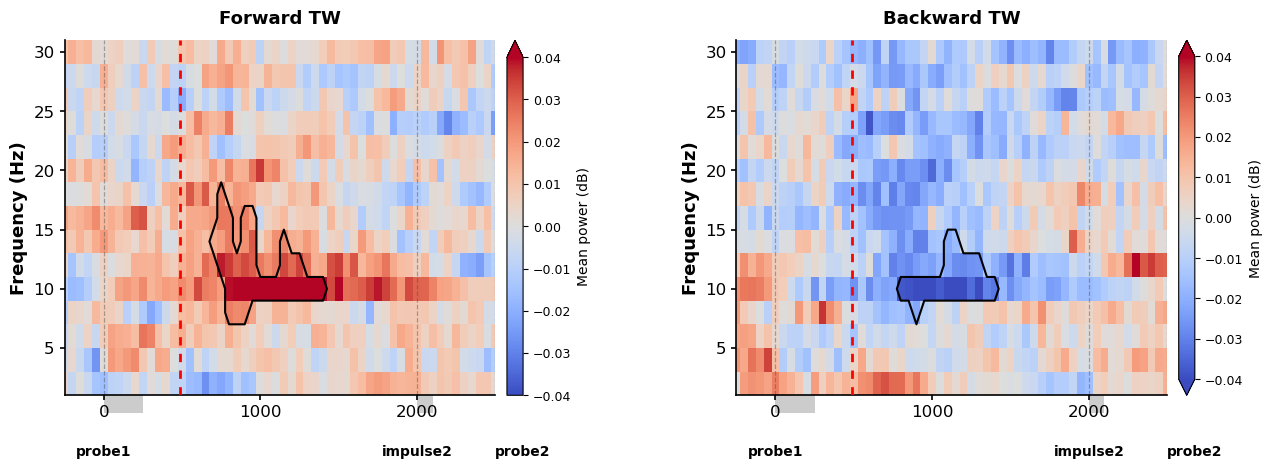

In [6]:
plots.plot_tf_maps(cue_maps, measures=MEASURES, **PLOT_WINDOWS['early'],
    limits=TF_LIMITS, diff_limits=TF_DIFF_LIMITS, cmap=TF_CMAP,
    show_sides=TF_SHOW_SIDES, panel_size=TF_PANEL_SIZE, rt_lines=rt_lines(cue_maps),
    output_dir=output_dir(), name='cue',  **PLOT_OPTIONS);


[cue | fw | alpha (8–12 Hz) | all]
time=[550.0, 1000.0] ms, p=0.0256
[cue | bw | alpha (8–12 Hz) | all]
time=[750.0, 1300.0] ms, p=0.0072
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/micheal/no-bl/cue_fw_bw_bands_1p55-4p3s_zero-1p8s.png


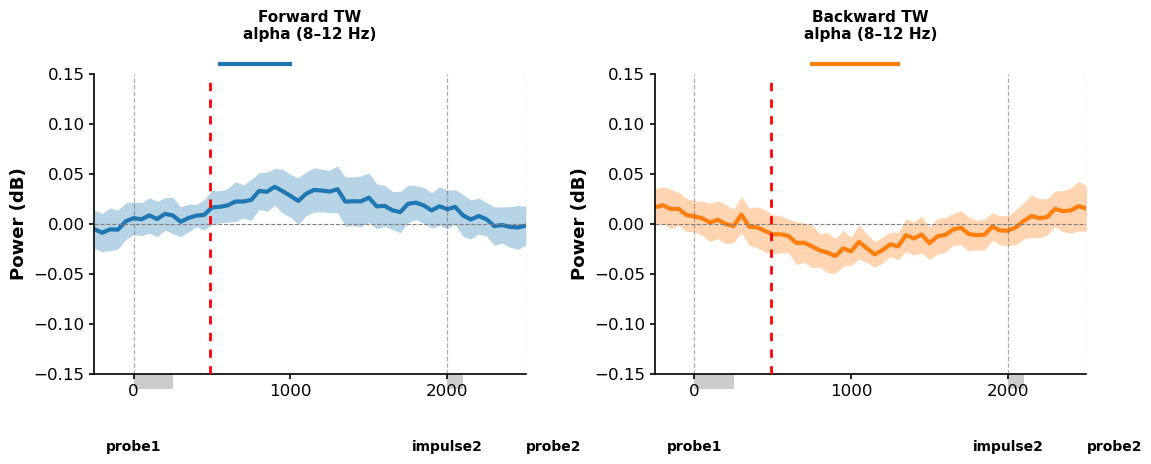

In [7]:
plots.plot_band_timeseries(cue_maps, group='difference', measures=MEASURES,
    freq_bands=CUE_FREQ_BANDS, measure_layout=CUE_MEASURE_LAYOUT, **PLOT_WINDOWS['early'], ylims=BAND_YLIMS,
    rt_lines=rt_lines(cue_maps), output_dir=output_dir(), name='cue',
     **PLOT_OPTIONS);


[cue_beta | fw | beta (14–30 Hz) | all]
No significant clusters. Minimum-p cluster (not significant):
time=[550.0, 800.0] ms, p=0.0548
[cue_beta | bw | beta (14–30 Hz) | all]
time=[550.0, 950.0] ms, p=0.0424
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/micheal/no-bl/cue_beta_fw_bw_bands_1p55-4p3s_zero-1p8s.png


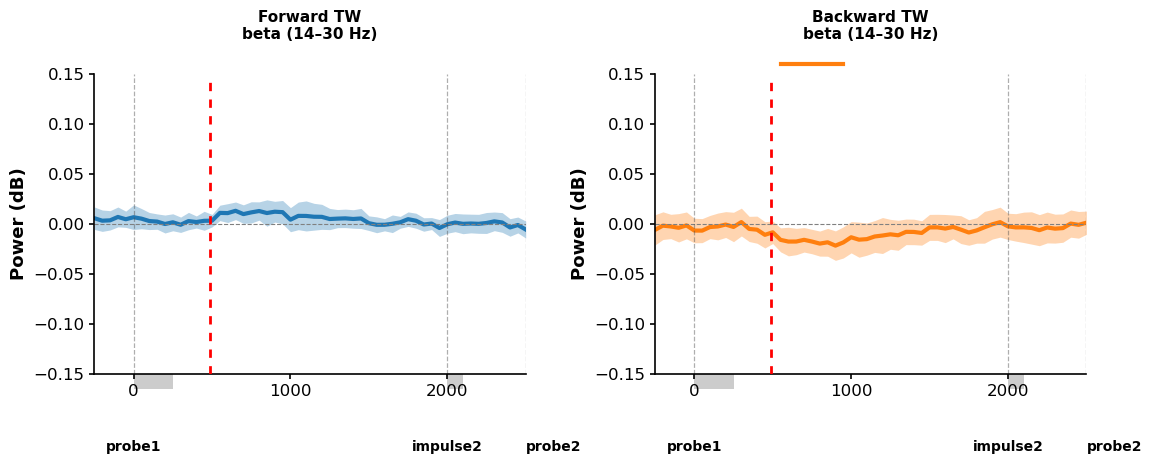

In [8]:
plots.plot_band_timeseries(cue_maps, group='difference', measures=MEASURES,
    freq_bands=[FREQ_BANDS[2]], measure_layout=CUE_MEASURE_LAYOUT, **PLOT_WINDOWS['early'], ylims=BAND_YLIMS,
    rt_lines=rt_lines(cue_maps), output_dir=output_dir(), name='cue_beta',
     **PLOT_OPTIONS);

## Hand-target same / different


[hand_target_early | fw | theta (2–6 Hz) | same]
time=[100.0, 350.0] ms, p=0.0428
time=[450.0, 950.0] ms, p=0.0008
[hand_target_early | fw | theta (2–6 Hz) | different]
time=[50.0, 1000.0] ms, p=0.0002
[hand_target_early | fw | theta (2–6 Hz) | same − different]
No significant clusters. Minimum-p cluster (not significant):
time=[1950.0, 1950.0] ms, p=0.4278
[hand_target_early | fw | alpha (8–12 Hz) | same]
time=[750.0, 1350.0] ms, p=0.0172
[hand_target_early | fw | alpha (8–12 Hz) | different]
No significant clusters. Minimum-p cluster (not significant):
time=[800.0, 950.0] ms, p=0.107
[hand_target_early | fw | alpha (8–12 Hz) | same − different]
time=[550.0, 1000.0] ms, p=0.0246
[hand_target_early | fw | beta (14–30 Hz) | same]
time=[650.0, 2350.0] ms, p=0.0002
[hand_target_early | fw | beta (14–30 Hz) | different]
time=[800.0, 2000.0] ms, p=0.0004
[hand_target_early | fw | beta (14–30 Hz) | same − different]
No significant clusters. Minimum-p cluster (not significant):
time=[550.0, 8

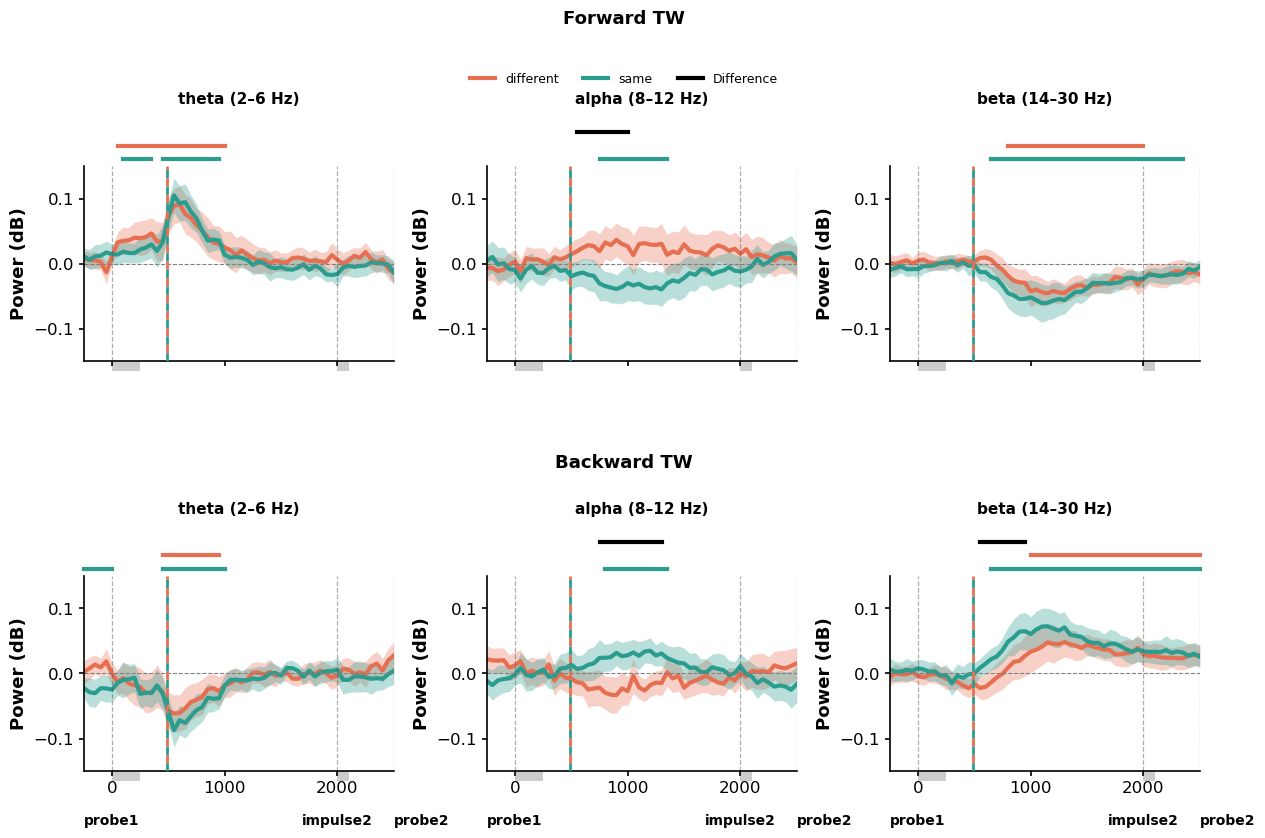

[hand_target_late | fw | theta (2–6 Hz) | same]
time=[500.0, 1000.0] ms, p=0.001
[hand_target_late | fw | theta (2–6 Hz) | different]
time=[450.0, 1050.0] ms, p=0.0018
[hand_target_late | fw | theta (2–6 Hz) | same − different]
No significant clusters. Minimum-p cluster (not significant):
time=[-250.0, -250.0] ms, p=0.5162
[hand_target_late | fw | alpha (8–12 Hz) | same]
No significant clusters. Minimum-p cluster (not significant):
time=[850.0, 850.0] ms, p=0.3454
[hand_target_late | fw | alpha (8–12 Hz) | different]
No significant clusters. Minimum-p cluster (not significant):
time=[200.0, 250.0] ms, p=0.1644
[hand_target_late | fw | alpha (8–12 Hz) | same − different]
No significant clusters. Minimum-p cluster (not significant):
time=[800.0, 1000.0] ms, p=0.0548
[hand_target_late | fw | beta (14–30 Hz) | same]
time=[850.0, 1300.0] ms, p=0.0002
[hand_target_late | fw | beta (14–30 Hz) | different]
time=[750.0, 1300.0] ms, p=0.0006
[hand_target_late | fw | beta (14–30 Hz) | same − diff

/media/dilay/T7/travelling_waves/tw/decoding_gpu/functions/tw_funcs/tw_plot_funcs.py:71: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv
  _, clusters, p_values, _ = permutation_cluster_1samp_test(
/media/dilay/T7/travelling_waves/tw/decoding_gpu/functions/tw_funcs/tw_plot_funcs.py:71: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv
  _, clusters, p_values, _ = permutation_cluster_1samp_test(
/media/dilay/T7/travelling_waves/tw/decoding_gpu/functions/tw_funcs/tw_plot_funcs.py:71: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv
  _, clusters, p_values, _ = permutation_cluster_1samp_test(
/media/dilay/T7/travelling_waves/tw/decoding_gpu/functions/tw_funcs/tw_plot_funcs.py:71: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv
  _, clusters, p_values, _ = permutation_cluster_1samp_test(


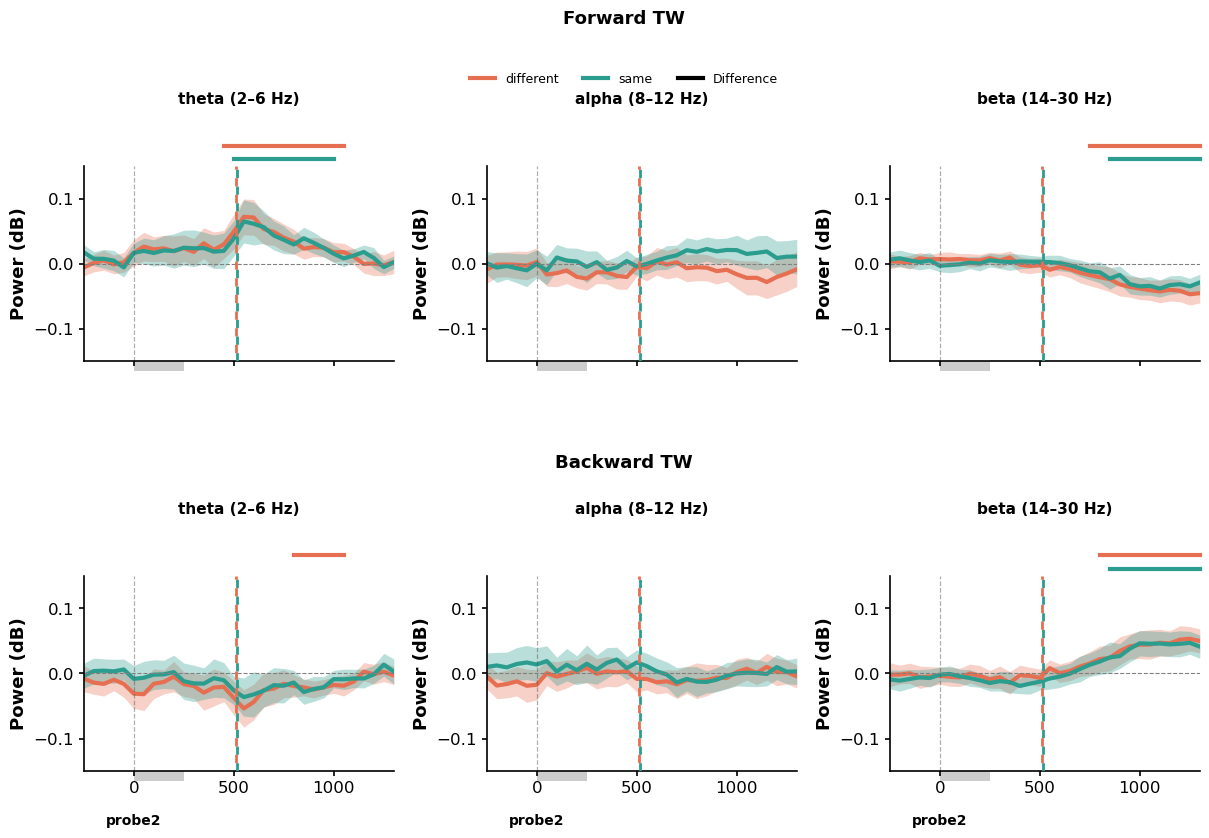

In [ ]:
for rt_type in ('early','late'):
    data = prepare_maps(alignment='hand', rt_type=rt_type, comparison='hand_target')
    lines = [(PROBE_ONSET[rt_type]+np.mean([np.mean(rt) for rt in data[key]['rt'][rt_type+'_rt'].values()]), color, key+' RT')
             for key,color in [('same','#2a9d8f'),('different','#e76f51')]]
    plots.plot_band_timeseries(data, group='difference', measures=MEASURES,
        freq_bands=FREQ_BANDS, **PLOT_WINDOWS[rt_type], ylims=HAND_YLIMS,
        tests=[('same',None),('different',None),('same','different')],
        colors={'same':'#2a9d8f','different':'#e76f51'}, rt_lines=lines,
        output_dir=output_dir(), name=f'hand_target_{rt_type}',
         **PLOT_OPTIONS);


## Response-hand-aligned band time courses


[hand_early | fw | theta (2–6 Hz) | all]
time=[0.0, 1150.0] ms, p=0.0002
[hand_early | fw | alpha (8–12 Hz) | all]
No significant clusters. Minimum-p cluster (not significant):
time=[2350.0, 2450.0] ms, p=0.1998
[hand_early | fw | beta (14–30 Hz) | all]
time=[750.0, 2350.0] ms, p=0.0002
[hand_early | bw | theta (2–6 Hz) | all]
time=[450.0, 1000.0] ms, p=0.0002
[hand_early | bw | alpha (8–12 Hz) | all]
No clusters found; no cluster time window or p-value to report.


/media/dilay/T7/travelling_waves/tw/decoding_gpu/tw_plot_funcs.py:65: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv


[hand_early | bw | beta (14–30 Hz) | all]
time=[750.0, 2500.0] ms, p=0.0002
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/micheal/no-bl/hand_early_fw_bw_bands_1p55-4p3s_zero-1p8s.png


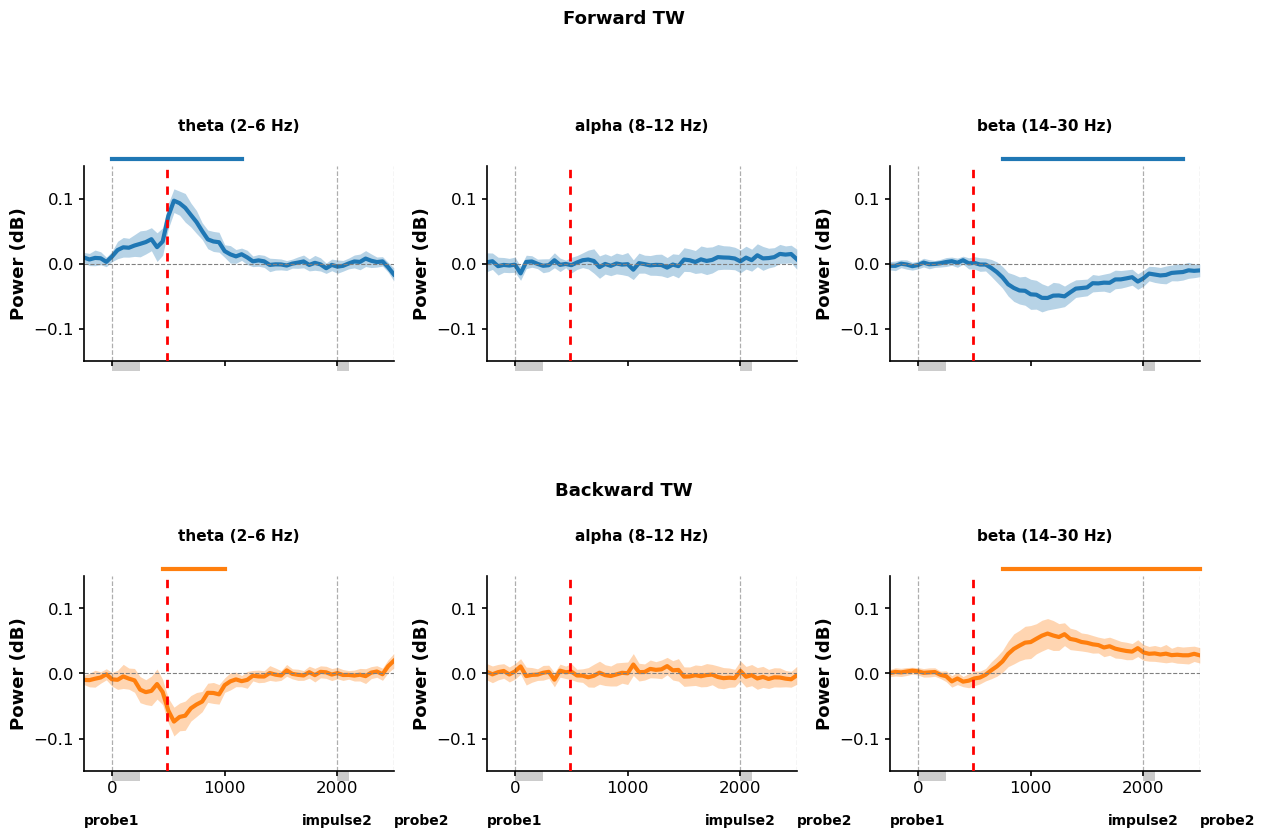

[hand_late | fw | theta (2–6 Hz) | all]
time=[450.0, 1150.0] ms, p=0.0004
[hand_late | fw | alpha (8–12 Hz) | all]
No significant clusters. Minimum-p cluster (not significant):
time=[50.0, 50.0] ms, p=0.2442
[hand_late | fw | beta (14–30 Hz) | all]
time=[700.0, 1300.0] ms, p=0.0004
[hand_late | bw | theta (2–6 Hz) | all]
time=[500.0, 1100.0] ms, p=0.0024
[hand_late | bw | alpha (8–12 Hz) | all]
No significant clusters. Minimum-p cluster (not significant):
time=[400.0, 400.0] ms, p=0.4812
[hand_late | bw | beta (14–30 Hz) | all]
time=[800.0, 1300.0] ms, p=0.0008
time=[100.0, 500.0] ms, p=0.0144
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/micheal/no-bl/hand_late_fw_bw_bands_4p05-5p6s_zero-4p3s.png


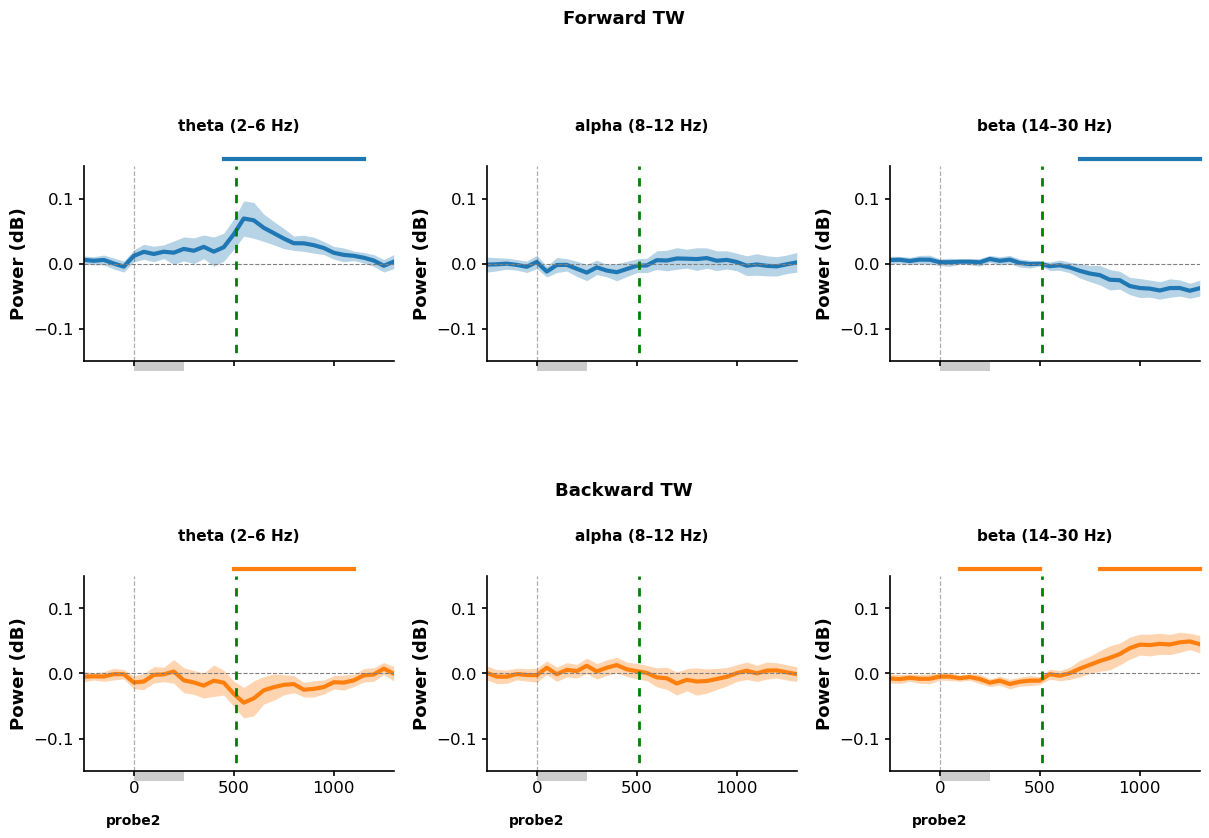

In [9]:
for rt_type in ('early','late'):
    data = prepare_maps(alignment='hand', rt_type=rt_type)['all']
    plots.plot_band_timeseries(data, group='difference', measures=MEASURES,
        freq_bands=FREQ_BANDS, **PLOT_WINDOWS[rt_type], ylims=HAND_YLIMS,
        rt_lines=rt_lines(data), output_dir=output_dir(), name=f'hand_{rt_type}',
         **PLOT_OPTIONS)


## Physical electrode-line mean: midline, baseline correction


[midline | fw | theta (2–6 Hz) | all]
time=[-850.0, 5750.0] ms, p=0.0002
[midline | fw | alpha (8–12 Hz) | all]
time=[-50.0, 1050.0] ms, p=0.0206
time=[1150.0, 2750.0] ms, p=0.0086
time=[3750.0, 5000.0] ms, p=0.0132
[midline | fw | beta (14–30 Hz) | all]
time=[-950.0, 5750.0] ms, p=0.0002
[midline | bw | theta (2–6 Hz) | all]
time=[-950.0, 200.0] ms, p=0.0004
time=[2850.0, 3650.0] ms, p=0.0152
[midline | bw | alpha (8–12 Hz) | all]
time=[-950.0, 150.0] ms, p=0.0078
time=[4950.0, 5750.0] ms, p=0.0242
[midline | bw | beta (14–30 Hz) | all]
time=[-950.0, 5750.0] ms, p=0.0002
[saved] /media/dilay/T7/travelling_waves/tw/result/figs/micheal/no-bl/midline_fw_bw_bands_-1p2-6s_zero-0s.png


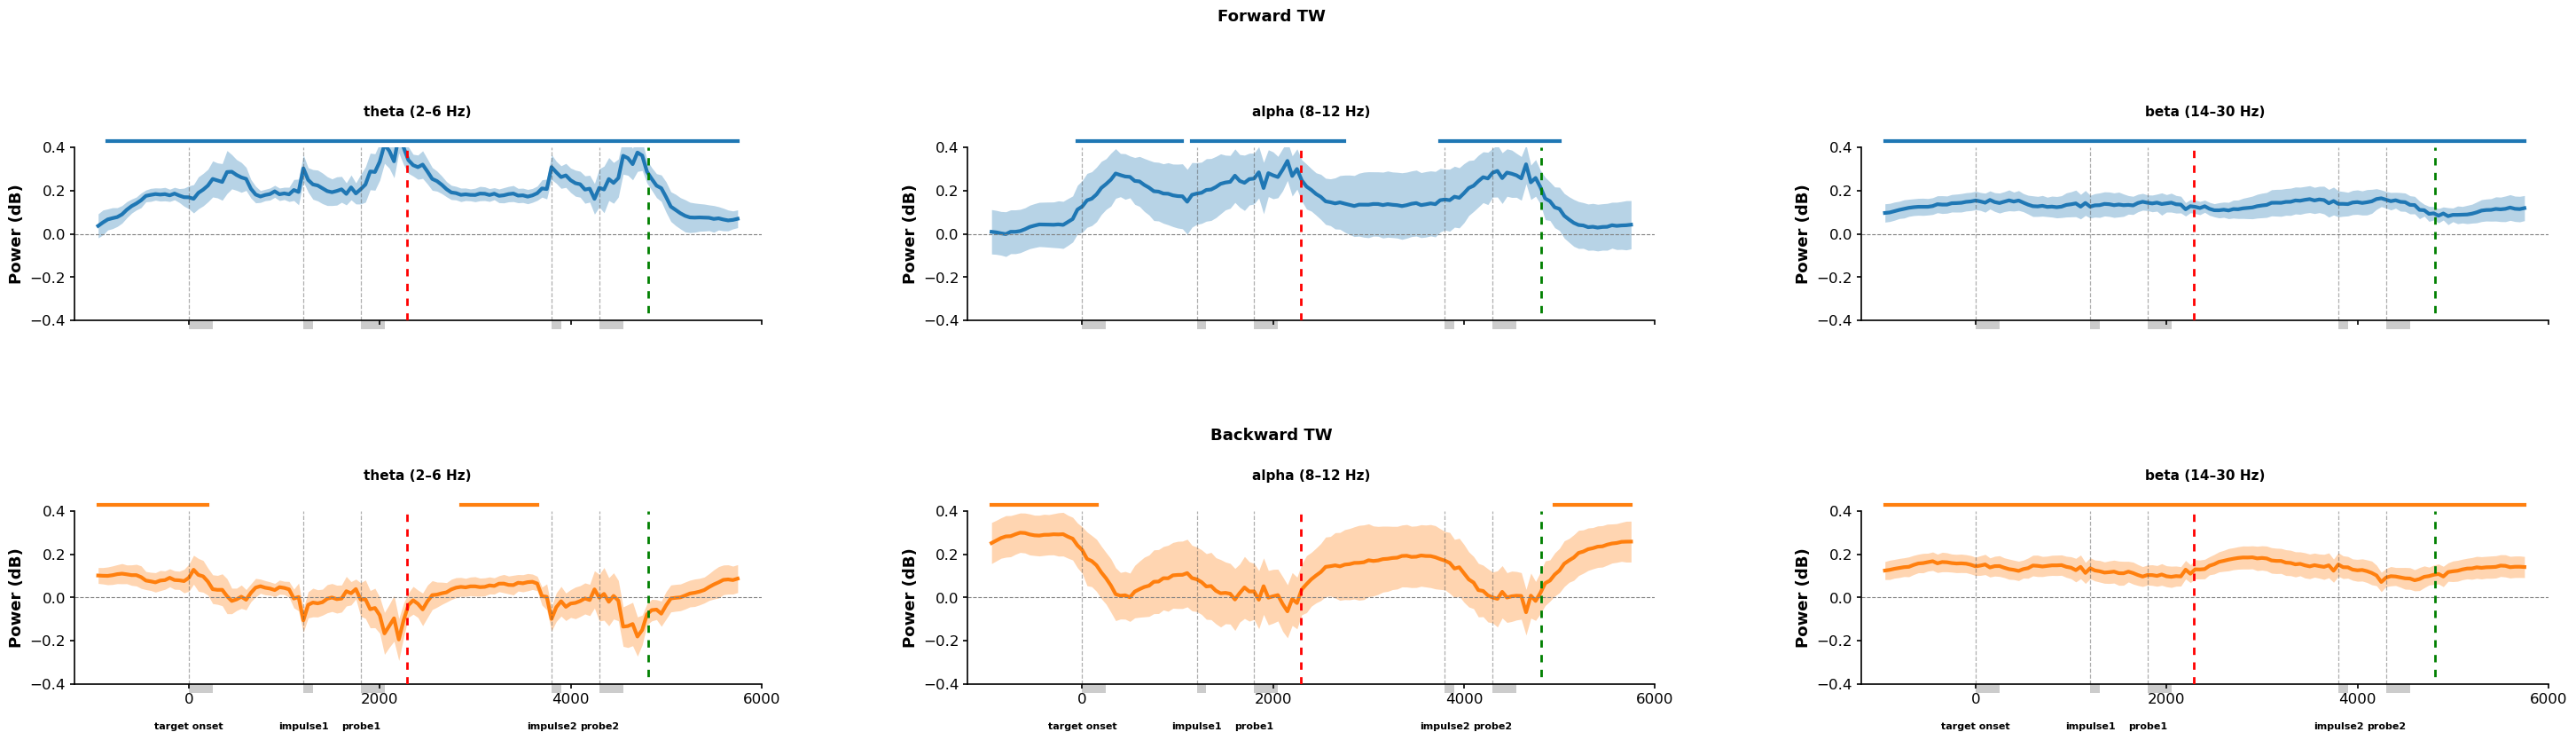

In [1]:
data = prepare_maps(alignment='physical', rt_type='early', groups={'selected':[5]})['all']
midline_result = plots.plot_band_timeseries(data, group='selected', measures=MEASURES,
    freq_bands=FREQ_BANDS, **PLOT_WINDOWS['whole'], ylims=POWER_YLIMS,
    rt_lines=rt_lines(data), output_dir=output_dir(), name='midline',
    event_label_rows=1, event_label_fontsize=8, panel_size=(12, 4.2),
    **PLOT_OPTIONS);
